In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../01 - DataPreparation/df_prepared.csv")

In [3]:
feature_cols = ['MinPlayers', 'MaxPlayers_log', 'Rating',  
       'IsReimplementation', 'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
       'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
       'Cat:Childrens',  'Age', 'AgeRec','NumOwned_log', 'NumAlternates_log', 
       'NumExpansions_log', 'NumImplementations_log', 'NumWant_log', 'AvgPlaytime_log']

In [4]:
X = df[feature_cols].copy()
y = df['GameWeight'].copy()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [6]:
preprocess = ColumnTransformer(
    transformers=[
        ("rating", OneHotEncoder(handle_unknown="ignore"), ["Rating"])
    ],
    remainder="passthrough"
)

model = Pipeline(steps=[
    ("prep", preprocess),
    ("tree", DecisionTreeRegressor(random_state=42))
])

In [7]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.420
RMSE: 0.577
R²:   0.476


Base Decision Tree Regressor predicts GameWeight with moderate accuracy: MAE = 0.420, RMSE = 0.577, and R² = 0.476, meaning it explains about 48% of the variance but still has noticeable error on individual predictions.

In [8]:
param_grid = {
    "tree__criterion": ["squared_error", "absolute_error"],
    "tree__max_depth": [6, 8, 10, 12],
    "tree__min_samples_split": [2, 5, 10, 20],
    "tree__min_samples_leaf": [20, 25, 30, 40],
    "tree__max_features": [None, "sqrt", 0.7],
    "tree__ccp_alpha": [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_model = grid.best_estimator_

print("Best params:", grid.best_params_)
print("Best CV MAE:", round(-grid.best_score_, 3))

Best params: {'tree__ccp_alpha': 0.0001, 'tree__criterion': 'absolute_error', 'tree__max_depth': 12, 'tree__max_features': None, 'tree__min_samples_leaf': 40, 'tree__min_samples_split': 2}
Best CV MAE: 0.331


Tuning selects a more regularized tree (max_depth=12 with large min_samples_leaf=25, plus small pruning via ccp_alpha=0.0001) and switches to MAE/absolute_error as the split criterion, achieving a best CV MAE of ~0.332, which is a clear improvement over the base model’s error.

In [9]:
y_pred = best_model.predict(X_test)

train_mae = mean_absolute_error(y_train, best_model.predict(X_train))
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Train MAE:", round(train_mae, 3))
print(f"\nTest MAE:  {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²:   {r2:.3f}")

Train MAE: 0.304

Test MAE:  0.328
Test RMSE: 0.450
Test R²:   0.681


The tuned decision tree regressor performs well on GameWeight: test MAE = 0.327 (close to train 0.294, so limited overfitting), RMSE = 0.452, and R² = 0.677, meaning it explains about 68% of the variance.

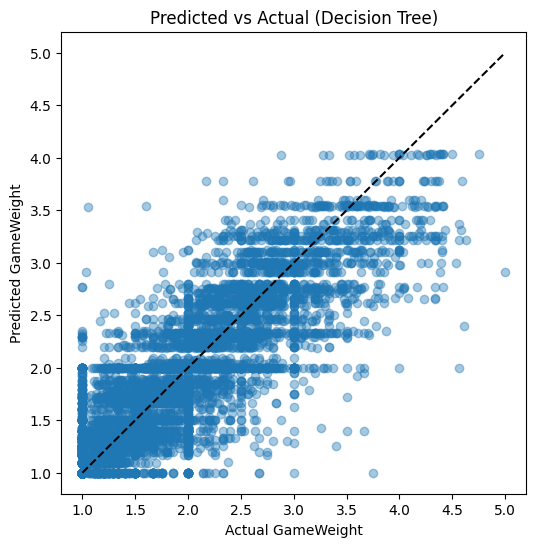

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.4)
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx], "k--")   # perfect prediction line
plt.xlabel("Actual GameWeight")
plt.ylabel("Predicted GameWeight")
plt.title("Predicted vs Actual (Decision Tree)")
plt.show()



The predicted vs actual plot shows a clear positive trend (many points near the diagonal), but with noticeable scatter and horizontal banding typical of decision trees.

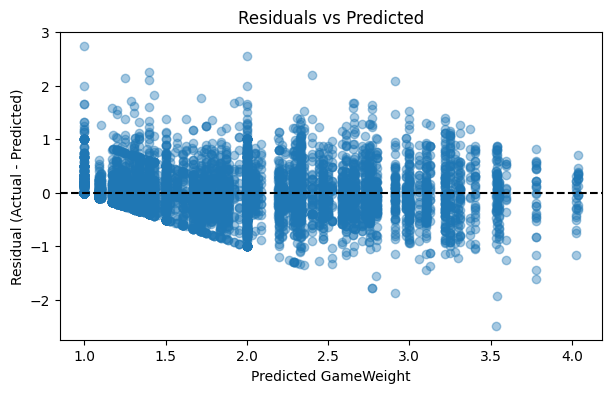

In [11]:
residuals = y_test - y_pred

plt.figure(figsize=(7,4))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, linestyle="--", color="k")
plt.xlabel("Predicted GameWeight")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted")
plt.show()


The residuals are mostly centered around 0 (no huge overall bias), but there’s a clear pattern: the model tends to underpredict at low predicted GameWeight (positive residuals) and overpredict at higher predicted values (negative residuals)

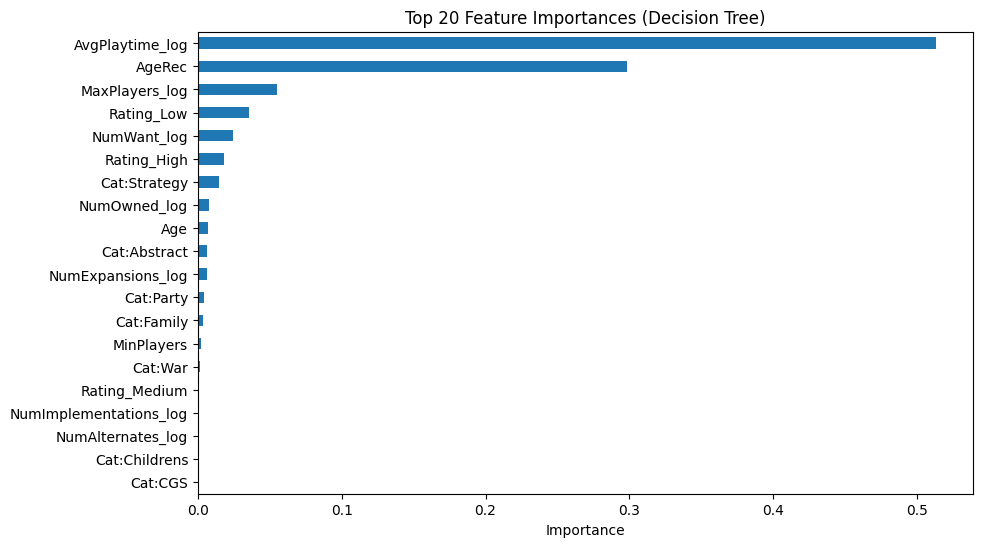

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

tree = best_model.named_steps["tree"]
prep = best_model.named_steps["prep"]

ohe = prep.named_transformers_["rating"]
rating_names = ohe.get_feature_names_out(["Rating"])

all_feature_names = list(rating_names) + [c for c in feature_cols if c != "Rating"]

importances = pd.Series(tree.feature_importances_, index=all_feature_names).sort_values()

plt.figure(figsize=(10,6))
importances.tail(20).plot(kind="barh")  # top 20 only, readable
plt.title("Top 20 Feature Importances (Decision Tree)")
plt.xlabel("Importance")
plt.show()


The feature importance plot shows the regressor is driven primarily by AvgPlaytime_log (dominant), followed by AgeRec, with smaller contributions from MaxPlayers_log and popularity/ratings signals (Rating_Low/High, NumWant_log, NumOwned_log). Category flags have only minor impact compared to the numeric/log-transformed features.